In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import casadi as ca
from IPython.display import clear_output, display
import time
import matplotlib.ticker as ticker
import os
import cvxpy as cp
from sklearn.linear_model import Ridge
import scipy.linalg
from scipy.linalg import cholesky, svd, solve
import pickle




def gaussian_kernel(X, Y, sigma=100):
    XX = np.sum(X ** 2, axis=0).reshape(-1, 1)
    YY = np.sum(Y ** 2, axis=0).reshape(1, -1)
    distances = XX + YY - 2 * np.dot(X.T, Y)
    return np.exp(-distances / (2 * sigma ** 2))

def gaussian_kernel_casadi(X1, X2, sigma=1.0):
    """
    Gaussian (RBF) kernel for CasADi symbolic variables.
    
    Args:
        X1: A CasADi MX matrix of shape (n_features, n_samples1)
        X2: A CasADi MX matrix of shape (n_features, n_samples2)
        sigma: The bandwidth parameter of the RBF kernel.
        
    Returns:
        A CasADi MX matrix of shape (n_samples1, n_samples2) representing the kernel matrix.
    """
    # Compute the squared L2 norm of the difference between each pair of points
    X1_sq = ca.sum1(X1**2).T  # Shape (n_samples1, 1)
    X2_sq = ca.sum1(X2**2).T  # Shape (n_samples2, 1)
    
    # Compute the squared Euclidean distance matrix
    sq_dists = X1_sq - 2 * (X1.T @ X2) + X2_sq.T
    
    # Compute the Gaussian kernel matrix
    K = ca.exp(-0.5 / sigma**2 * sq_dists)
    
    return K

def chiuso_kernel(X, Y, sigma, lambda_, T_ini):
    # Initialize the kernel matrix
    K = np.zeros((X.shape[1], Y.shape[1]))
    
    # Vectorized computation over the T_ini blocks
    for i in range(T_ini - 1, -1, -1):
        exp_factor = np.exp(-(T_ini - i -1) * lambda_)
        X_sub = X[i*5:(i+1)*5, :]
        Y_sub = Y[i*5:(i+1)*5, :]

        K += exp_factor * gaussian_kernel(X_sub, Y_sub, sigma)
    
    return K

def chiuso_kernel_casadi(X, Y, sigma, lambda_, T_ini):
    # Initialize the kernel matrix
    K = ca.MX.zeros(X.shape[1], Y.size2())
    
    # Vectorized computation over the T_ini blocks
    for i in range(T_ini - 1, -1, -1):
        exp_factor = ca.exp(-(T_ini - i -1) * lambda_)
        X_sub = X[i*5:(i+1)*5, :]
        Y_sub = Y[i*5:(i+1)*5, :]
        
        K += exp_factor * gaussian_kernel_casadi(X_sub, Y_sub, sigma)
    
    return K

In [4]:
# Perform the swingu up with a feedback controller, to gather data
np.random.seed(4)

# whether to show the animation, faster to run without
show_animation = 0
# whether to show the predictions, cleaner plots without
show_predictions = 0
# which methods to run
select_methods = {
    "Fixed Length Kernel clDeePC": 0,
    "Transient Kernel clDeePC": 1,
    "Kernel DeePC": 0,
    "clDeePC": 0,
    "Koopman": 0,
    "Koopman DeePC": 0,
}

# Parameters for the feedback controller
ksu = 1.05
kcw = 1.5
kvw = 5
kem = 1e-13
eta = 1.0

m = 4.78
M = 10.47
L = 0.3
g = 9.81
Vd = 2*m*g*L

xmax = 0.7
vmax = 10

# PID controller parameters
Kp_p = -3.2
Ki_p = -0.0
Kd_p = 0.5

Kp_c = 0.2
Ki_c = -0.005
Kd_c = 0.5

integral_p = 0.0
integral_c = 0.0

stabilise = 0
doomed = 0
excitation = 0.02
numSteps = 1000

y = np.zeros(numSteps)
x = np.zeros((4, numSteps))

u = np.random.normal(0, 1, numSteps)

reset_time = []
failed = []
seed = 3

refpos = 0

if show_animation:
    env = gym.make("InvertedPendulum-v4-swingup", render_mode="human")
else:
    env = gym.make("InvertedPendulum-v4-swingup")
obs, info = env.reset(seed=seed)

for k in range(numSteps):
    obs += np.random.normal(0, 0.00001, (np.size(obs)))
    angle = obs[1]  # Angle of the pendulum
    dangle = obs[3]
    pos = obs[0]
    speed = obs[2]
    error_p = -angle 
    error_c = refpos - pos  
    integral_c += error_c
            
    angle = obs[1] - np.pi
    V = 0.5 * m * L**2 * dangle**2 + m * g * L *(1 - np.cos(angle))
    angle = obs[1]
    
    # if the pendulum is close to the upright position, switch to the stabilising controller
    if np.abs(obs[1]) < 0.2:
        if stabilise == 0:
            refpos = pos
            integral_c = 0
        stabilise = 1

                
    if not stabilise:
        # the swing up controller
        u[k] = -ksu * np.sign(dangle * np.cos(angle)) + kcw * np.sign(pos) * np.log(1 - np.abs(pos)/(xmax*2)) + \
                kem * (np.exp(np.abs(V - eta * Vd)) - 1) * np.sign(V - Vd) * np.sign(dangle * np.cos(angle)) + np.random.normal(0, excitation)
    else:
        # the stabilising controller
        u[k] = Kp_p * error_p + Ki_p * integral_p + Kd_p * dangle \
            + Kp_c * error_c + Ki_c * integral_c + Kd_c * speed + np.random.normal(0, 0.05)
            
            
    x[:,k] = obs
    
    # Clip the control input to the action space limits
    u[k] = np.clip(u[k], env.action_space.low[0], env.action_space.high[0])
    obs, reward, done, truncated, info = env.step([u[k]])
    
    if show_animation:
        time.sleep(0.05)
        
    if done or truncated or (k + 1)  % 100 == 0:
        seed += 1
        if np.abs(obs[1]) > 0.1:
            failed += [k]
        obs, info = env.reset(seed = seed)
        reset_time += [k]
        stabilise = 0
        integral_c = 0
        
        
env.close()

y = x
y_ref = y[:, 0:reset_time[0] + 1]
u_ref = u[0:reset_time[0] + 1]
ref = np.vstack((u_ref.T, y_ref))


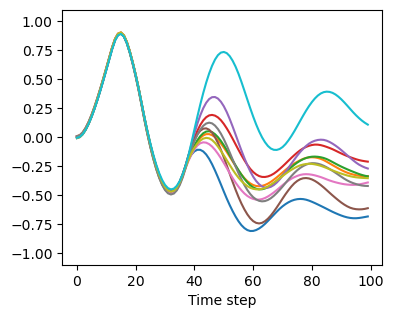

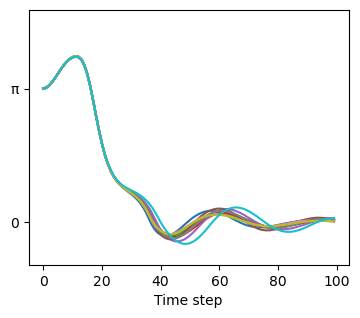

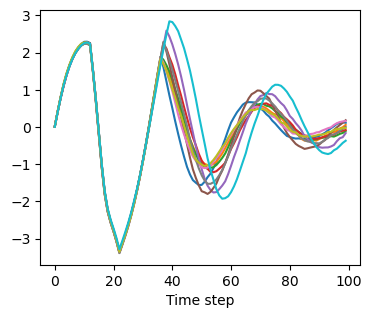

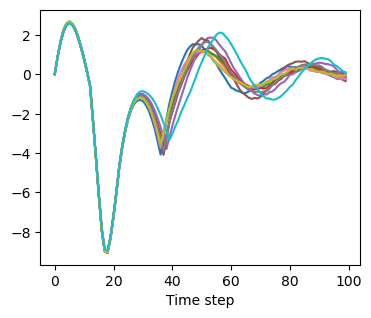

In [12]:
# Plot the data gathered

# Initialize figures outside the loop
plt.figure(1,figsize=(4, 3))
plt.xlabel('Time step')
plt.ylim([-1.1, 1.1])
plt.subplots_adjust(left=0.2, bottom=0.15, right=1, top=1) 

plt.figure(2,figsize=(4, 3))
plt.xlabel('Time step')
plt.ylim([-1, 5.0])
plt.subplots_adjust(left=0.2, bottom=0.15, right=1, top=1) 
plt.gca().yaxis.set_major_locator(ticker.MultipleLocator(base=np.pi))
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: 
    'π' if val == np.pi else '{:.0g}π'.format(val / np.pi) if val != 0 else '0'))

plt.figure(3,figsize=(4, 3))
plt.xlabel('Time step')
plt.subplots_adjust(left=0.2, bottom=0.15, right=1, top=1) 

plt.figure(4,figsize=(4, 3))
plt.xlabel('Time step')
plt.subplots_adjust(left=0.2, bottom=0.15, right=1, top=1) 

# Set last_t initially to zero
last_t = -1

# Loop through reset times to plot sections together
for t in reset_time:
    if t in failed:
        last_t = t
        continue
    # Extract sections for y and u
    y_section = y[:, last_t+1:t+1]
    u_section = u[last_t+1:t+1]
    last_t = t
    numSteps_section = len(u_section)
    
    # Plot for 'position'
    plt.figure(1)
    plt.plot(range(numSteps_section), y_section[0, :], '-')
    
    # Plot for 'angle'
    plt.figure(2)
    plt.plot(range(numSteps_section), y_section[1, :], '-')
    
    # Plot for 'linear velocity'
    plt.figure(3)
    plt.plot(range(numSteps_section), y_section[2, :], '-')
    
    # Plot for 'angular velocity'
    plt.figure(4)
    plt.plot(range(numSteps_section), y_section[3, :], '-')

# Display legends for each plot
plt.figure(1)
plt.savefig('plots\swing up/ref/position_plot.pdf')  # Save as PDF

plt.figure(2)
plt.savefig('plots\swing up/ref/angle_plot.pdf')

plt.figure(3)
plt.savefig('plots\swing up/ref/linear_velocity_plot.pdf')

plt.figure(4)
plt.savefig('plots\swing up/ref/angular_velocity_plot.pdf')

# Optionally display the plots
plt.show()


In [ ]:
# Form the matrices used by the closed-loop DeePC and the Fixed Length Kernel clDeePC and the Koopman

N_c = 1
T_ini = 1
L_c = T_ini + N_c  # Hankel matrix row
sigma_c = 9
gamma_c = 1e-6
T_sim = 100

U_p_c = []
U_f_c = []
Y_p_c = []
Y_f_c = []

last_t = -1
for t in reset_time:
    if t in failed:
        last_t = t
        continue
    y_section = y[:, last_t+1:t+1]
    u_section = u[last_t+1:t+1]
    last_t = t
    
    numSteps_section = len(u_section)
    
    if numSteps_section - L_c > 0:
        H_u_c = np.zeros((L_c, numSteps_section - L_c + 1))
        H_y_c = np.zeros((L_c * 4, numSteps_section - L_c + 1))
        for i in range(L_c):
            H_u_c[i, :] = u_section[i:i + numSteps_section - L_c + 1]
            H_y_c[i*4:(i+1)*4, :] = y_section[:, i:i + numSteps_section - L_c + 1]
        
        U_p_c += [H_u_c[:T_ini, :]]
        U_f_c += [H_u_c[T_ini:, :]]
        
        Y_p_c += [H_y_c[:T_ini*4, :]]
        Y_f_c += [H_y_c[T_ini*4:, :]]
    
U_p_c = np.hstack(U_p_c)
U_f_c = np.hstack(U_f_c)
Y_p_c = np.hstack(Y_p_c)
Y_f_c = np.hstack(Y_f_c)
    
H_c = np.vstack((U_p_c, Y_p_c, U_f_c, Y_f_c))
D_c = np.vstack((U_p_c, Y_p_c))
    
# Gram matrix
K_c = gaussian_kernel(D_c, D_c, sigma_c)

Y_lift = gaussian_kernel(D_c, np.vstack((U_f_c, Y_f_c)), sigma_c)

H_c_c = len(H_c[0])

# M = Y_lift @ np.linalg.pinv(np.vstack((K_c, U_f_c)))
# A = M[:, :H_c_c]
# B = M[:, H_c_c:]

G = np.vstack((K_c, U_f_c)) @ np.vstack((K_c, U_f_c)).T# + 1e-6 * np.eye(K_c.shape[0] + U_p_c.shape[0])

cond_G = np.linalg.cond(G)


V = Y_lift @ np.vstack((K_c, U_f_c)).T
cond_V = np.linalg.cond(V)

ridge = Ridge(alpha=1e-10)  # Regularization strength (alpha)
ridge.fit(G.T, V.T)  # Fit the model

# Extract the solution
M_ridge = ridge.coef_

A = M_ridge[:, :K_c.shape[0]]
B = M_ridge[:, K_c.shape[0]:]

eig_A = np.linalg.eigvals(A)
min_eig_A = np.min(np.abs(eig_A))
max_eig_A = np.max(np.abs(eig_A))

n, m = B.shape
N_o = 40

def stable_matrix_power(A, exponent, regularization=1e-10):
    # Apply regularization (small perturbation to avoid large condition numbers)
    A_reg = A + regularization * np.eye(A.shape[0])

    # Schur decomposition: A = Q @ T @ Q^H
    Q, T = scipy.linalg.schur(A_reg)
    
    # Compute T^exponent
    T_powered = np.linalg.matrix_power(T, exponent)
    
    # Reconstruct the matrix A^exponent
    A_powered = Q @ T_powered @ np.linalg.inv(Q)
    
    return A_powered

M1 = Y_f_c @ np.linalg.inv(K_c + gamma_c * np.eye(H_c_c))
M3 = Y_f_c @ np.linalg.pinv(D_c)

# Construct the A matrix
A_blk = np.zeros((N_o * 4, n))
for i in range(N_o):
    #A_powered = stable_matrix_power(A, i + 1)
    #A_blk[i * 4:(i + 1) * 4, :] = M1 @ A_powered
    A_blk[i * 4:(i + 1) * 4, :] = M1 @ np.linalg.matrix_power(A, i)

# Construct the B matrix
B_blk = np.zeros((N_o * 4, N_o * m))
for i in range(N_o):
    for j in range(i):  # Only fill lower triangular part
        #A_powered = stable_matrix_power(A, i - j)
        #B_blk[i * 4:(i + 1) * 4, j * m:(j + 1) * m] = M1 @ A_powered @ B
        B_blk[i * 4:(i + 1) * 4, j * m:(j + 1) * m] = M1 @ np.linalg.matrix_power(A, i - j - 1) @ B
        
cond_A_blk = np.linalg.cond(A_blk)
cond_B_blk = np.linalg.cond(B_blk)

U_A, S_A, VT_A = np.linalg.svd(A_blk)
U_B, S_B, VT_B = np.linalg.svd(B_blk)



pass

KeyboardInterrupt: 

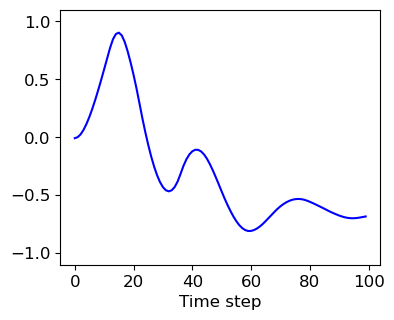

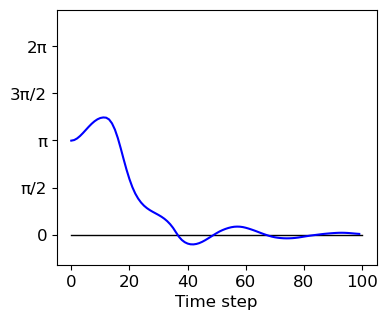

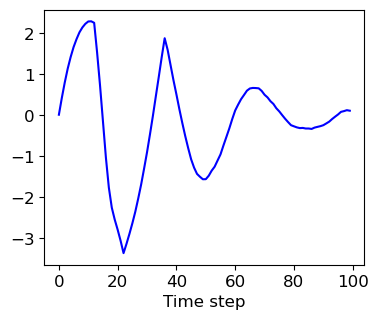

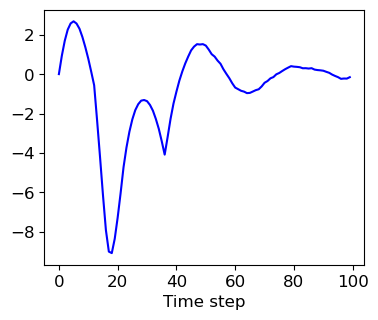

In [5]:
# Create the plot where the performace of the various methods will be shown, and a trajectory from the data

plt.ion()  # Turn on interactive mode

# Create four figures
fig1, ax1 = plt.subplots(figsize=(4, 3))
plt.ylim([-1.1, 1.1])
plt.xlabel('Time step', fontsize=12)
plt.subplots_adjust(left=0.2, bottom=0.15, right=1, top=1) 
plt.tick_params(axis='both', labelsize=12)

fig2, ax2 = plt.subplots(figsize=(4, 3))
plt.ylim([-1, 7.5])
plt.xlabel('Time step', fontsize=12)
plt.subplots_adjust(left=0.2, bottom=0.15, right=1, top=1) 
plt.gca().yaxis.set_major_locator(ticker.MultipleLocator(base=np.pi / 2))
plt.gca().yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda val, pos: (
        "0" if val == 0 else
        "π" if np.isclose(val, np.pi) else
        "2π" if np.isclose(val, 2 * np.pi) else
        "π/2" if np.isclose(val, np.pi / 2) else
        "3π/2" if np.isclose(val, 3 * np.pi / 2) else
        f"{val / np.pi:.0g}π"
    ))
)
plt.tick_params(axis='both', labelsize=12)
plt.plot([0, 100], [0, 0], color='black', linewidth=1)

fig3, ax3 = plt.subplots(figsize=(4, 3))
plt.xlabel('Time step', fontsize=12)
plt.subplots_adjust(left=0.2, bottom=0.15, right=1, top=1) 
plt.tick_params(axis='both', labelsize=12)

fig4, ax4 = plt.subplots(figsize=(4, 3))
plt.xlabel('Time step', fontsize=12)
plt.subplots_adjust(left=0.2, bottom=0.15, right=1, top=1) 
plt.tick_params(axis='both', labelsize=12)

ax1.plot(np.arange(0, len(ref[0])), ref[1,:], 'b', linewidth=1.5)#, label='Training Data', alpha=0.5)
ax2.plot(np.arange(0, len(ref[0])), ref[2,:], 'b', linewidth=1.5)#, label='Training Data', alpha=0.5)
ax3.plot(np.arange(0, len(ref[0])), ref[3,:], 'b', linewidth=1.5)#, label='Reference', alpha=0.5)
ax4.plot(np.arange(0, len(ref[0])), ref[4,:], 'b', linewidth=1.5)#, label='Reference', alpha=0.5)


In [ ]:
# Kernel clDeePC Fixed Length
if select_methods["Fixed Length Kernel clDeePC"]:
    env = gym.make("InvertedPendulum-v4-swingup", render_mode="rgb_array")
    env = gym.wrappers.RecordVideo(env=env, video_folder='video', name_prefix='Kernel clDeePC no ref closed-loop swingup', step_trigger=lambda x: True)

    obs, info = env.reset(seed=3)
    env.start_video_recorder()

    lb = env.action_space.low[0]
    ub = env.action_space.high[0]

    y1_c = obs
    y_ini = obs
    u_ini = [ref[0,0]]
    u_c = np.zeros((T_sim,))

    colors = ['b', 'c', 'm', 'y', 'k']

    weighted_steps = 10
    for i in range(T_sim):
        N_o = int(len(ref[0])) - i
        N_o = min(N_o, 40)
        opti = ca.Opti()
        objective = 0
        # state costs
        Q = np.kron(np.eye(N_o),np.diag([0, 1, 10, 0.1, 0.1]))
        # weigh only the last steps
        Q[:, :-(weighted_steps*5)] = 0        
        x_c = opti.variable(5 * N_o + 5 * T_ini)
        objective += ca.mtimes([x_c[5*T_ini:].T, Q, x_c[5*T_ini:]])
        # input costs
        R = np.kron(np.eye(N_o),np.diag([0.1, 0, 0, 0, 0]))
        objective += ca.mtimes([x_c[5*T_ini:].T, R, x_c[5*T_ini:]])
        
        constraints = []
        for k in range(N_o):
            constraints.append(x_c[5*T_ini + 5*k + 1 : 5*T_ini + 5*k + 5] == M1 @ gaussian_kernel_casadi(D_c, x_c[5*T_ini + 5*(k-1) : 5*T_ini + 5*(k-1) + 5], sigma_c))
        constraints.append(x_c[5*T_ini::5] >= lb)
        constraints.append(x_c[5*T_ini::5] <= ub)
        constraints.append(x_c[:T_ini] == u_ini)
        constraints.append(x_c[T_ini:5*T_ini] == y_ini)
        
        for constraint in constraints:
            opti.subject_to(constraint)

        # Set the objective in Opti
        opti.minimize(objective)
        
        # Set initial guesses for the variables
        initial_guess = np.zeros(5 * N_o + 5 * T_ini)
        opti.set_initial(x_c, initial_guess)
        
        # Solver options
        opts = {'ipopt.print_level': 0, 'print_time': 0}
        opti.solver('ipopt', opts)
        
        # Solve the problem
        sol = opti.solve()
        
        # Extract the solution
        u_c_opt = sol.value(x_c[5*T_ini::5])
        chunks = [sol.value(x_c[i:i + 5]) for i in range(5*T_ini, (N_o + T_ini) * 5, 5)]
        y_pred_ = [chunk[-4:] for chunk in chunks]
        y_pred = np.concatenate(y_pred_)
        
        obs, reward, done, truncated, info = env.step([u_ini[-1]])
        obs += np.random.normal(0, 0.00001, (np.size(obs)))
        
        if N_o == 1:
            u1_c = u_c_opt
        else:
            u1_c = u_c_opt[0]
        u_c[i] = u_ini[-1]
        y1_old = y1_c
        y1_c = obs
        
        u_ini = np.hstack((u_ini, u1_c))[1:]
        y_ini = np.hstack((y_ini, y1_c))[4:]
        

        ax1.plot([i, i+1], [y1_old[0], y1_c[0]], 'r-', linewidth=1.5)
        ax2.plot([i, i+1], [y1_old[1], y1_c[1]], 'r-', linewidth=1.5)
        ax3.plot([i, i+1], [y1_old[2], y1_c[2]], 'r-', linewidth=1.5)
        ax4.plot([i, i+1], [y1_old[3], y1_c[3]], 'r-', linewidth=1.5)
        
        if show_predictions and i % 10 == 0:
            y_pred = y_pred.reshape((4,-1),order='F')
            color = "r"
            ax1.plot(np.arange(i+1, i +1 + N_o), y_pred[0,:], color + '--', linewidth=0.5)
            ax2.plot(np.arange(i+1, i +1 + N_o), y_pred[1,:], color + '--', linewidth=0.5)
            ax3.plot(np.arange(i+1, i +1 + N_o), y_pred[2,:], color + '--', linewidth=0.5)
            ax4.plot(np.arange(i+1, i +1 + N_o), y_pred[3,:], color + '--', linewidth=0.5)
            
        # Redraw the updated plots
        fig1.canvas.draw()
        fig1.canvas.flush_events()
        fig2.canvas.draw()
        fig2.canvas.flush_events()
        fig3.canvas.draw()
        fig3.canvas.flush_events()
        fig4.canvas.draw()
        fig4.canvas.flush_events()
        clear_output(wait=True)
        display(fig1)
        display(fig2)
        display(fig3)
        display(fig4)
        plt.pause(0.001)

    env.close_video_recorder()
    env.close()

    plt.ioff()
    plt.show()

    


In [ ]:
# the clDeePC
if select_methods["clDeePC"]:
    env = gym.make("InvertedPendulum-v4-swingup", render_mode="rgb_array")
    env = gym.wrappers.RecordVideo(env=env, video_folder='video', name_prefix='clDDPC closed-loop swingup', step_trigger=lambda x: True)

    obs, info = env.reset(seed=3)
    env.start_video_recorder()

    lb = env.action_space.low[0]
    ub = env.action_space.high[0]

    y1_c = obs
    y_ini = obs
    u_ini = [ref[0,0]]
    u_c = np.zeros((T_sim,))

    weighted_steps = 10

    for i in range(T_sim):
    
        N_o = int(len(ref[0])) - i
        N_o = min(N_o, 40)
        opti = ca.Opti()
        objective = 0
        
        Q = np.kron(np.eye(N_o),np.diag([0, 0.01, 10, 0.1, 0.1]))
        Q[:, :-(weighted_steps*5)] = 0        
        x_c = opti.variable(5 * N_o + 5 * T_ini)
        objective += ca.mtimes([x_c[5*T_ini:].T, Q, x_c[5*T_ini:]])
        
        R = np.kron(np.eye(N_o),np.diag([0.1, 0, 0, 0, 0]))
        objective += ca.mtimes([x_c[5*T_ini:].T, R, x_c[5*T_ini:]])
        
        constraints = []
        for k in range(N_o):
            constraints.append(x_c[5*T_ini + 5*k + 1 : 5*T_ini + 5*k + 5] == M3 @ x_c[5*T_ini + 5*(k-1) : 5*T_ini + 5*(k-1) + 5])
        constraints.append(x_c[5*T_ini::5] >= lb)
        constraints.append(x_c[5*T_ini::5] <= ub)
        constraints.append(x_c[:T_ini] == u_ini)
        constraints.append(x_c[T_ini:5*T_ini] == y_ini)
        
        for constraint in constraints:
            opti.subject_to(constraint)

        # Set the objective in Opti
        opti.minimize(objective)
        
        # Set initial guesses for the variables
        initial_guess = np.zeros(5 * N_o + 5 * T_ini)
        opti.set_initial(x_c, initial_guess)
        
        # Solver options
        opts = {'ipopt.print_level': 0, 'print_time': 0}
        opti.solver('ipopt', opts)
        
        # Solve the problem
        sol = opti.solve()
        
        # Extract the solution
        u_c_opt = sol.value(x_c[5*T_ini::5])
        chunks = [sol.value(x_c[i:i + 5]) for i in range(5*T_ini, (N_o + T_ini) * 5, 5)]
        y_pred_ = [chunk[-4:] for chunk in chunks]
        y_pred = np.concatenate(y_pred_)
        
        obs, reward, done, truncated, info = env.step([u_ini[-1]])
        obs += np.random.normal(0, 0.00001, (np.size(obs)))
        
        if N_o == 1:
            u1_c = u_c_opt
        else:
            u1_c = u_c_opt[0]
        u_c[i] = u_ini[-1]
        y1_old = y1_c
        y1_c = obs
        
        u_ini = np.hstack((u_ini, u1_c))[1:]
        y_ini = np.hstack((y_ini, y1_c))[4:]

        ax1.plot([i, i+1], [y1_old[0], y1_c[0]], 'g-', linewidth=1.5)    
        ax2.plot([i, i+1], [y1_old[1], y1_c[1]], 'g-', linewidth=1.5)    
        ax3.plot([i, i+1], [y1_old[2], y1_c[2]], 'g-', linewidth=1.5)    
        ax4.plot([i, i+1], [y1_old[3], y1_c[3]], 'g-', linewidth=1.5)

        if show_predictions and i % 10 == 0:
            y_pred = y_pred.reshape((4,-1),order='F')
            color = "g"
            ax1.plot(np.arange(i+1, i +1 + N_o), y_pred[0,:], color + '--', linewidth=0.5)
            ax2.plot(np.arange(i+1, i +1 + N_o), y_pred[1,:], color + '--', linewidth=0.5)
            ax3.plot(np.arange(i+1, i +1 + N_o), y_pred[2,:], color + '--', linewidth=0.5)
            ax4.plot(np.arange(i+1, i +1 + N_o), y_pred[3,:], color + '--', linewidth=0.5)
            
        # Redraw the updated plots
        fig1.canvas.draw()
        fig1.canvas.flush_events()
        fig2.canvas.draw()
        fig2.canvas.flush_events()
        fig3.canvas.draw()
        fig3.canvas.flush_events()
        fig4.canvas.draw()
        fig4.canvas.flush_events()
        clear_output(wait=True)
        display(fig1)
        display(fig2)
        display(fig3)
        display(fig4)
        plt.pause(0.001)

    env.close_video_recorder()
    env.close()

    plt.ioff()
    plt.show()


In [ ]:
# Calculate the matrices for the Kernel DeePC and the Koopman DeePC

N_o = 40

L_o = T_ini + N_o  # Hankel matrix row
u_ini = np.zeros((T_ini,))
y_ini = np.zeros((T_ini*4,))
gamma = 0.00001
sigma_o = 10
sigma_o_koopman = 50
lambda_g = 1e-3
lambda_k = 1e8

U_p_o = []
U_f_o = []
Y_p_o = []
Y_f_o = []

last_t = -1
for t in reset_time:
    y_section = y[:, last_t+1:t+1]
    u_section = u[last_t+1:t+1]
    last_t = t
    
    numSteps_section = len(u_section)
    if numSteps_section - L_o > 0:
        H_u_o = np.zeros((L_o, numSteps_section - L_o + 1))
        H_y_o = np.zeros((L_o * 4, numSteps_section - L_o + 1))
        for i in range(L_o):
            H_u_o[i, :] = u_section[i:i + numSteps_section - L_o + 1]
            H_y_o[i*4:(i+1)*4, :] = y_section[:, i:i + numSteps_section - L_o + 1]
        
        U_p_o += [H_u_o[:T_ini, :]]
        U_f_o += [H_u_o[T_ini:, :]]
        
        Y_p_o += [H_y_o[:T_ini*4, :]]
        Y_f_o += [H_y_o[T_ini*4:, :]]
    
U_p_o = np.hstack(U_p_o)
U_f_o = np.hstack(U_f_o)
Y_p_o = np.hstack(Y_p_o)
Y_f_o = np.hstack(Y_f_o)
    
H_o = np.vstack((U_p_o, Y_p_o, U_f_o, Y_f_o))
D_o = np.vstack((U_p_o, Y_p_o, U_f_o))
D_o_koopman = np.vstack((U_p_o, Y_p_o))
    
# Gram matrix
K_o = gaussian_kernel(D_o, D_o, sigma_o) + gamma * np.eye(len(H_o[0]))

H_c_o = len(H_o[0])

M_o = Y_f_o @ np.linalg.inv(K_o + gamma * np.eye(H_c_o))

K_koopman_deepc = gaussian_kernel(D_o_koopman[:, :-N_o], D_o_koopman, sigma_o_koopman)

M_Koopman_DeePC = Y_f_o @ np.linalg.pinv(np.vstack((K_koopman_deepc, U_f_o)))

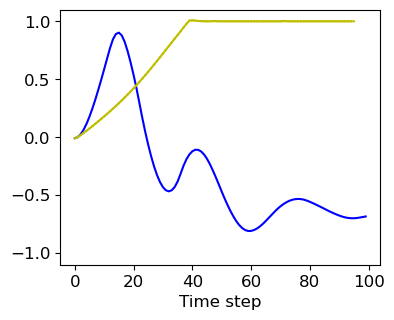

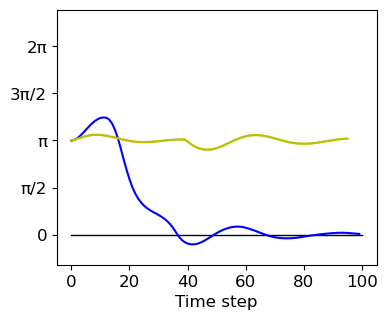

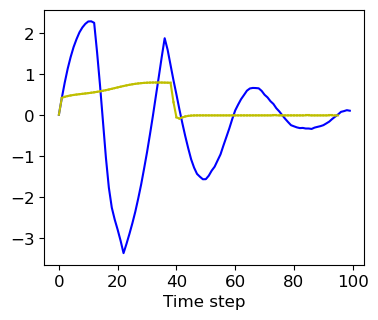

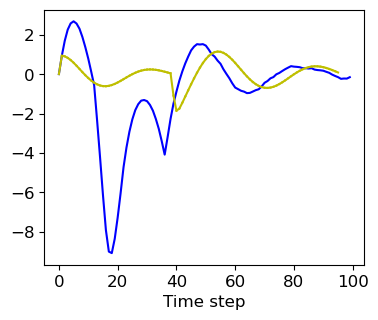

SystemError: <built-in function Opti_solve> returned a result with an error set

In [ ]:
# The Kernel DeePC
if select_methods["Kernel DeePC"]:
    env = gym.make("InvertedPendulum-v4-swingup", render_mode="rgb_array")
    env = gym.wrappers.RecordVideo(env=env, video_folder='video', name_prefix='Kernel DeePC closed-loop swingup', step_trigger=lambda x: True)

    obs, info = env.reset(seed=3)
    env.start_video_recorder()

    lb = env.action_space.low[0]
    ub = env.action_space.high[0]

    y1_o = obs
    y_ini = obs
    u_ini = [ref[0,0]]
    u_o = np.zeros((T_sim,))

    weighted_steps = 10

    for i in range(T_sim):
        opti = ca.Opti()
        objective = 0
        
        Q = np.kron(np.eye(N_o),np.diag([0.01, 10, 0.1, 0.1]))
        Q[:, :-(weighted_steps*4)] = 0        
        
        x_o = opti.variable(N_o + 5 * T_ini)
        y_f = opti.variable(4 * N_o)
        #g_o = opti.variable(H_c_o)
        objective = 0
        #objective += ca.mtimes([(Y_f_o @ g_o).T, Q, (Y_f_o @ g_o)]) # state costs
        objective += ca.mtimes([x_o[5 * T_ini:].T, x_o[5 * T_ini:]]) * 0.1 # input costs
        #objective += lambda_g * ca.sumsqr(g_o)
        gaussian_kernel_ = gaussian_kernel_casadi(D_o, x_o, sigma_o)
        #objective += lambda_k * ca.sumsqr(K_o @ g_o - gaussian_kernel_)
        objective += ca.mtimes([y_f.T, Q, y_f])
        constraints = []
        #constraints.append(K_o @ g_o == gaussian_kernel_)
        constraints.append(y_f == M_o @ gaussian_kernel_)
        constraints.append(x_o[5*T_ini:] >= lb)
        constraints.append(x_o[5*T_ini:] <= ub)
        constraints.append(x_o[:T_ini] == u_ini)
        constraints.append(x_o[T_ini:5*T_ini] == y_ini)
        
        for constraint in constraints:
            opti.subject_to(constraint)

        # Set the objective in Opti
        opti.minimize(objective)
        
        # Set initial guesses for the variables
        #initial_guess = np.zeros(N_o + H_c_o + 5 * T_ini)
        #opti.set_initial(ca.vertcat(x_o, g_o), initial_guess)
        initial_guess = np.zeros(5 * N_o + 5 * T_ini)
        opti.set_initial(ca.vertcat(x_o, y_f), initial_guess)
        
        # Solver options
        opts = {'ipopt.print_level': 0, 'print_time': 0}
        opti.solver('ipopt', opts)
        
        # Solve the problem
        sol = opti.solve()
        
        # Extract the solution
        u_o_opt = sol.value(x_o[5 * T_ini:N_o + 5 * T_ini])
        #g_o_opt = sol.value(g_o)

        #y_pred = (Y_f_o @ g_o_opt).reshape((4,-1),order='F')
        y_pred = sol.value(y_f).reshape((4,-1),order='F')
        
        obs, reward, done, truncated, info = env.step([u_ini[-1]])
        obs += np.random.normal(0, 0.00001, (np.size(obs)))
        
        if N_o == 1:
            u1_o = u_o_opt
        else:
            u1_o = u_o_opt[0]
            
        u_o[i] = u_ini[-1]
        y1_old = y1_o
        y1_o = obs
        
        u_ini = np.hstack((u_ini, u1_o))[1:]
        y_ini = np.hstack((y_ini, y1_o))[4:]

        ax1.plot([i, i+1], [y1_old[0], y1_o[0]], 'y-', linewidth=1.5)    
        ax2.plot([i, i+1], [y1_old[1], y1_o[1]], 'y-', linewidth=1.5)    
        ax3.plot([i, i+1], [y1_old[2], y1_o[2]], 'y-', linewidth=1.5)    
        ax4.plot([i, i+1], [y1_old[3], y1_o[3]], 'y-', linewidth=1.5)
        
        if show_predictions and i % 10 == 0:
            y_pred = y_pred.reshape((4,-1),order='F')
            color = "y"
            for ax, yp in zip([ax1, ax2, ax3, ax4], y_pred):
                ax.plot(np.arange(i + 1, i + 1 + N_o), np.where(np.arange(i + 1, i + 1 + N_o) > 100, np.nan, yp), color + '--', linewidth=0.5)

        # Redraw the updated plots
        fig1.canvas.draw()
        fig1.canvas.flush_events()
        fig2.canvas.draw()
        fig2.canvas.flush_events()
        fig3.canvas.draw()
        fig3.canvas.flush_events()
        fig4.canvas.draw()
        fig4.canvas.flush_events()
        clear_output(wait=True)
        display(fig1)
        display(fig2)
        display(fig3)
        display(fig4)
        plt.pause(0.001)

    env.close_video_recorder()
    env.close()

    plt.ioff()
    plt.show()



In [ ]:
# Koopman DeePC
if select_methods["Koopman DeePC"]:
    env = gym.make("InvertedPendulum-v4-swingup", render_mode="rgb_array")

    obs, info = env.reset(seed=3)

    lb = env.action_space.low[0]
    ub = env.action_space.high[0]

    y1_c = obs
    y_ini = obs
    u_ini = [ref[0,0]]
    u_c = np.zeros((T_sim,))
    
    nz = K_c.shape[0]

    weighted_steps = 10
    
    N_o = 40

    Q = np.kron(np.eye(N_o), np.diag([1, 10, 0.1, 0.1]))
    Q[:, :-(weighted_steps * 4)] = 0

    # input costs
    R = np.kron(np.eye(N_o), np.diag([0.1]))    
    
    for i in range(T_sim):
        z0 = gaussian_kernel(D_o_koopman[:, :-N_o], np.hstack((u_ini, y_ini)).reshape(5, 1), sigma_o_koopman)
        
        # CVXPY problem formulation
        u_f = cp.Variable(N_o)  # control inputs

        objective = 0
        objective += cp.quad_form(M_Koopman_DeePC @ cp.vstack([z0, cp.reshape(u_f, (-1, 1))]), Q)
        objective += cp.quad_form(u_f, R)
                    
        # Constraints
        constraints = []
        constraints.append(u_f >= lb)
        constraints.append(u_f <= ub)

        # Define the problem
        problem = cp.Problem(cp.Minimize(objective), constraints)

        # Solve the problem using a convex solver
        problem.solve(solver="SCS", verbose=True)

        # Extract the solution
        u_c_opt = u_f.value
        y_f = M_Koopman_DeePC @ np.vstack([z0, u_c_opt.reshape(-1, 1)])
        y_pred = y_f.reshape((4, -1), order='F')
        
        obs, reward, done, truncated, info = env.step([u_ini[-1]])
        obs += np.random.normal(0, 0.00001, (np.size(obs)))
        
        if N_o == 1:
            u1_c = u_c_opt
        else:
            u1_c = u_c_opt[0]
        u_c[i] = u_ini[-1]
        y1_old = y1_c
        y1_c = obs
        
        u_ini = np.hstack((u_ini, u1_c))[1:]
        y_ini = np.hstack((y_ini, y1_c))[4:]
        

        ax1.plot([i, i+1], [y1_old[0], y1_c[0]], 'purple', linewidth=1.5)
        ax2.plot([i, i+1], [y1_old[1], y1_c[1]], 'purple', linewidth=1.5)
        ax3.plot([i, i+1], [y1_old[2], y1_c[2]], 'purple', linewidth=1.5)
        ax4.plot([i, i+1], [y1_old[3], y1_c[3]], 'purple', linewidth=1.5)
        
        if show_predictions and i % 10 == 0:
            y_pred = y_pred.reshape((4,-1),order='F')
            color = "purple"
            for ax, yp in zip([ax1, ax2, ax3, ax4], y_pred):
                ax.plot(np.arange(i + 1, i + 1 + N_o), np.where(np.arange(i + 1, i + 1 + N_o) > 100, np.nan, yp), linestyle='--', color='purple', linewidth=0.5)
            
        # Redraw the updated plots
        fig1.canvas.draw()
        fig1.canvas.flush_events()
        fig2.canvas.draw()
        fig2.canvas.flush_events()
        fig3.canvas.draw()
        fig3.canvas.flush_events()
        fig4.canvas.draw()
        fig4.canvas.flush_events()
        clear_output(wait=True)
        display(fig1)
        display(fig2)
        display(fig3)
        display(fig4)
        plt.pause(0.001)

    env.close()

    plt.ioff()
    plt.show()

In [6]:
# Calculate the matrices for the Transient Kernel DeePC

N_c = 1
T_ini = 1
slope = 20
sigma_c = 9
gamma_c = 1e-6
T_sim = 100
lambda_ = 2


ref = np.vstack((u_ref.T, y_ref))
M1t = dict()
D_ct = dict()
sigma_ct = dict()

for T_ini in range(1,51):
    U_p_c = []
    U_f_c = []
    Y_p_c = []
    Y_f_c = []
    last_t = -1
    L_c = T_ini + N_c
    sigma_ct[T_ini] = sigma_c
    for t in reset_time:
        if t in failed:
            last_t = t
            continue
        y_section = y[:, last_t+1:t+1]
        u_section = u[last_t+1:t+1]
        last_t = t
        
        numSteps_section = len(u_section)
        
        if numSteps_section - L_c > 0:
            H_u_c = np.zeros((L_c, numSteps_section - L_c + 1))
            H_y_c = np.zeros((L_c * 4, numSteps_section - L_c + 1))
            for i in range(L_c):
                H_u_c[i, :] = u_section[i:i + numSteps_section - L_c + 1]
                H_y_c[i*4:(i+1)*4, :] = y_section[:, i:i + numSteps_section - L_c + 1]
            
            U_p_c += [H_u_c[:T_ini, :]]
            U_f_c += [H_u_c[T_ini:, :]]
            
            Y_p_c += [H_y_c[:T_ini*4, :]]
            Y_f_c += [H_y_c[T_ini*4:, :]]
    
    U_p_c = np.hstack(U_p_c)
    U_f_c = np.hstack(U_f_c)
    Y_p_c = np.hstack(Y_p_c)
    Y_f_c = np.hstack(Y_f_c)
        
    H_c = np.vstack((U_p_c, Y_p_c, U_f_c, Y_f_c))
    D_ct[T_ini] = []
    for i in range(T_ini):
        D_ct[T_ini] += [U_p_c[i, :]]
        D_ct[T_ini] += [Y_p_c[i*4:(i+1)*4, :]]
        
    D_ct[T_ini] = np.vstack(D_ct[T_ini])
        
    # Gram matrix
    K_c = chiuso_kernel(D_ct[T_ini], D_ct[T_ini], sigma_ct[T_ini], lambda_, T_ini)

    H_c_c = len(H_c[0])

    M1t[T_ini] = Y_f_c @ np.linalg.inv(K_c + gamma_c * np.eye(H_c_c))
    

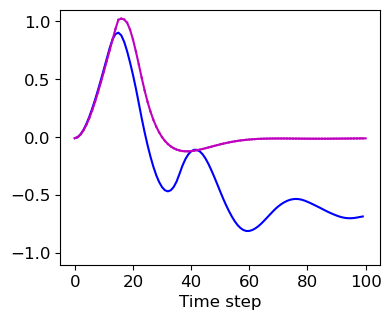

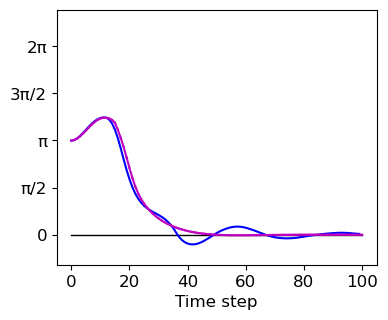

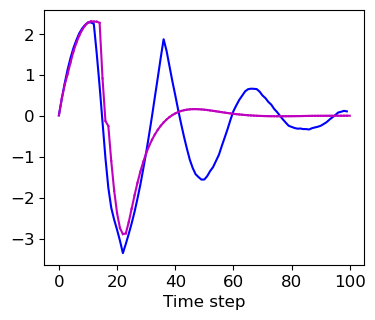

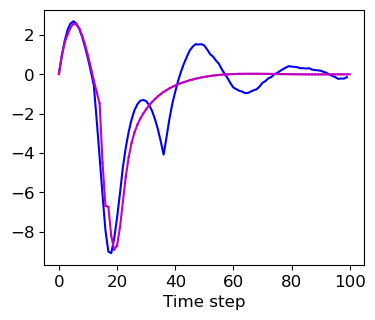

Moviepy - Building video d:\Useless\ETH\Semester Project\code\python\video\Kernel clDeePC no ref closed-loop swingup-step-0.mp4.
Moviepy - Writing video d:\Useless\ETH\Semester Project\code\python\video\Kernel clDeePC no ref closed-loop swingup-step-0.mp4



Moviepy - Done !
Moviepy - video ready d:\Useless\ETH\Semester Project\code\python\video\Kernel clDeePC no ref closed-loop swingup-step-0.mp4


In [7]:
# The Transient Kernel clDeePC
if select_methods["Transient Kernel clDeePC"]:
    T_ini = 1
    env = gym.make("InvertedPendulum-v4-swingup", render_mode="rgb_array")

    obs, info = env.reset(seed=3)

    lb = env.action_space.low[0]
    ub = env.action_space.high[0]

    y1_c = obs
    y_ini = obs
    y1_old = y1_c
    u_ini = [ref[0,0]]
    u_c = np.zeros((T_sim,))

    colors = ['b', 'c', 'm', 'y', 'k']

    weighted_steps = 10
    start_weight = 35
        
    for i in range(T_sim):

        N_o = int(len(ref[0])) - i
        N_o = min(N_o, 40)
        opti = ca.Opti()
        objective = 0
        
        Q = np.kron(np.eye(N_o),np.diag([0, 1, 10, 0.1, 0.1]))
        Q[:, :-(weighted_steps*5)] = 0        
        x_c = opti.variable(5 * N_o + 5 * T_ini)
        objective += ca.mtimes([x_c[5*T_ini:].T, Q, x_c[5*T_ini:]])
        R = np.kron(np.eye(N_o),np.diag([0.1, 0, 0, 0, 0]))
        objective += ca.mtimes([x_c[5*T_ini:].T, R, x_c[5*T_ini:]])
        
        constraints = []
        for k in range(N_o):
            constraints.append(x_c[5*T_ini + 5*k + 1 : 5*T_ini + 5*k + 5] == M1t[k+1] @ chiuso_kernel_casadi(D_ct[k+1], x_c[: 5*T_ini + 5*k], sigma_ct[k+1], lambda_, k+1))
        constraints.append(x_c[5*T_ini::5] >= lb)
        constraints.append(x_c[5*T_ini::5] <= ub)
        constraints.append(x_c[:T_ini] == u_ini)
        constraints.append(x_c[T_ini:5*T_ini] == y_ini)
        
        for constraint in constraints:
            opti.subject_to(constraint)

        # Set the objective in Opti
        opti.minimize(objective)
        
        # Set initial guesses for the variables
        initial_guess = np.zeros(5 * N_o + 5 * T_ini)
        opti.set_initial(x_c, initial_guess)
        
        # Solver options
        opts = {'ipopt.print_level': 0, 'print_time': 0}
        opti.solver('ipopt', opts)
        
        # Solve the problem
        sol = opti.solve()
        
        # Extract the solution
        u_c_opt = sol.value(x_c[5*T_ini::5])
        chunks = [sol.value(x_c[i:i + 5]) for i in range(5*T_ini, (N_o + T_ini) * 5, 5)]
        y_pred_ = [chunk[-4:] for chunk in chunks]
        y_pred = np.concatenate(y_pred_)
        
        obs, reward, done, truncated, info = env.step([u_ini[-1]])
        obs += np.random.normal(0, 0.00001, (np.size(obs)))
        
        if N_o == 1:
            u1_c = u_c_opt
        else:
            u1_c = u_c_opt[0]
        u_c[i] = u_ini[-1]
        y1_c = obs
        
        u_ini = np.hstack((u_ini, u1_c))[1:]
        y_ini = np.hstack((y_ini, y1_c))[4:]
        
        if show_predictions and i % 10 == 0:
            y_pred = y_pred.reshape((4,-1),order='F')
            color = "m"
            ax1.plot(np.arange(i+1, i +1 + N_o), y_pred[0,:], color + '--', linewidth=0.5)
            ax2.plot(np.arange(i+1, i +1 + N_o), y_pred[1,:], color + '--', linewidth=0.5)
            ax3.plot(np.arange(i+1, i +1 + N_o), y_pred[2,:], color + '--', linewidth=0.5)
            ax4.plot(np.arange(i+1, i +1 + N_o), y_pred[3,:], color + '--', linewidth=0.5)
        
        #if i % 5 == 0 and i > 0:
            
        ax1.plot([i, i+1], [y1_old[0], y1_c[0]], 'm-', linewidth=1.5)        
        ax2.plot([i, i+1], [y1_old[1], y1_c[1]], 'm-', linewidth=1.5)        
        ax3.plot([i, i+1], [y1_old[2], y1_c[2]], 'm-', linewidth=1.5)        
        ax4.plot([i, i+1], [y1_old[3], y1_c[3]], 'm-', linewidth=1.5)
        y1_old = y1_c
    
        # Redraw the updated plots
        fig1.canvas.draw()
        fig1.canvas.flush_events()
        fig2.canvas.draw()
        fig2.canvas.flush_events()
        fig3.canvas.draw()
        fig3.canvas.flush_events()
        fig4.canvas.draw()
        fig4.canvas.flush_events()
        clear_output(wait=True)
        display(fig1)
        display(fig2)
        display(fig3)
        display(fig4)
        plt.pause(0.001)

    env.close()

    plt.ioff()
    plt.show()

        


In [ ]:
# Koopman
if select_methods["Koopman"]:
    env = gym.make("InvertedPendulum-v4-swingup", render_mode="rgb_array")

    obs, info = env.reset(seed=3)

    lb = env.action_space.low[0]
    ub = env.action_space.high[0]

    y1_c = obs
    y_ini = obs
    u_ini = [ref[0,0]]
    u_c = np.zeros((T_sim,))
    
    nz = K_c.shape[0]

    weighted_steps = 10
    
    N_o = 40

    Q = np.kron(np.eye(N_o), np.diag([1, 10, 0.1, 0.1]))
    Q[:, :-(weighted_steps * 4)] = 0

    # input costs
    R = np.kron(np.eye(N_o), np.diag([0.1]))
    
    H = R + B_blk.T @ Q @ B_blk
    G = 2 * A_blk.T @ Q @ B_blk
    
    
    for i in range(T_sim):
        z0 = gaussian_kernel(D_c, np.hstack((u_ini, y_ini)).reshape(5, 1), sigma_c)
        
        # CVXPY problem formulation
        u_f = cp.Variable(N_o)  # control inputs

        objective = 0
    
        objective += cp.quad_form(u_f, cp.psd_wrap(H)) + z0.T @ G @ u_f
                
        # Constraints
        constraints = []
        constraints.append(u_f >= lb)
        constraints.append(u_f <= ub)

        # Define the problem
        problem = cp.Problem(cp.Minimize(objective), constraints)

        # Solve the problem using a convex solver
        problem.solve(solver="SCS", verbose=True)

        # Extract the solution
        u_c_opt = u_f.value
        y_f = A_blk @ z0 + B_blk @ u_c_opt.reshape((N_o, 1))
        y_pred = y_f.reshape((4, -1), order='F')
        
        obs, reward, done, truncated, info = env.step([u_ini[-1]])
        obs += np.random.normal(0, 0.00001, (np.size(obs)))
        
        if N_o == 1:
            u1_c = u_c_opt
        else:
            u1_c = u_c_opt[0]
        u_c[i] = u_ini[-1]
        y1_old = y1_c
        y1_c = obs
        
        u_ini = np.hstack((u_ini, u1_c))[1:]
        y_ini = np.hstack((y_ini, y1_c))[4:]
        

        ax1.plot([i, i+1], [y1_old[0], y1_c[0]], 'c-', linewidth=1.5)
        ax2.plot([i, i+1], [y1_old[1], y1_c[1]], 'c-', linewidth=1.5)
        ax3.plot([i, i+1], [y1_old[2], y1_c[2]], 'c-', linewidth=1.5)
        ax4.plot([i, i+1], [y1_old[3], y1_c[3]], 'c-', linewidth=1.5)
        
        if show_predictions and i % 10 == 0:
            y_pred = y_pred.reshape((4,-1),order='F')
            color = "c"
            for ax, yp in zip([ax1, ax2, ax3, ax4], y_pred):
                ax.plot(np.arange(i + 1, i + 1 + N_o), np.where(np.arange(i + 1, i + 1 + N_o) > 100, np.nan, yp), color + '--', linewidth=0.5)
            
        # Redraw the updated plots
        fig1.canvas.draw()
        fig1.canvas.flush_events()
        fig2.canvas.draw()
        fig2.canvas.flush_events()
        fig3.canvas.draw()
        fig3.canvas.flush_events()
        fig4.canvas.draw()
        fig4.canvas.flush_events()
        clear_output(wait=True)
        display(fig1)
        display(fig2)
        display(fig3)
        display(fig4)
        plt.pause(0.001)

    env.close()

    plt.ioff()
    plt.show()

    


KeyboardInterrupt: 

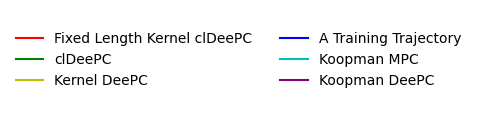

In [3]:
# Save the plot and create a legend-only figure

# Create dummy lines for the legend
fig_legend = plt.figure(figsize=(1, 1)) 
line1, = plt.plot([], [], 'r-', label='Fixed Length Kernel clDeePC')
line2, = plt.plot([], [], 'g-', label='clDeePC')
line3, = plt.plot([], [], 'y-', label='Kernel DeePC')
line4, = plt.plot([], [], 'b-', label='A Training Trajectory') 
#line5, = plt.plot([], [], 'm--', dashes=[3, 5], label='Transient Kernel clDeePC')
line5, = plt.plot([], [], 'c-', label='Koopman MPC')
line6, = plt.plot([], [], 'purple', label='Koopman DeePC')
plt.axis('off')
plt.subplots_adjust(top = 1, bottom = 0, right = 1, left = 0, 
            hspace = 0, wspace = 0)# Create a figure specifically for the legend
legend = fig_legend.legend(handles=[line1, line2, line3, line4, line5, line6], loc='center', ncol=2, frameon=False)

# Remove axes from the legend figure
fig_legend.gca().axis('off')

# Save the legend-only figure
fig_legend.savefig('plots/swing up/no ref/test/legend_only.pdf', bbox_inches='tight', dpi=300)
plt.show()

# if not show_predictions:
#     fig1.savefig('plots/swing up/no ref/test\position.pdf')
#     fig2.savefig('plots/swing up/no ref/test/angle.pdf')
#     fig3.savefig('plots/swing up/no ref/test/linear velocity.pdf')
#     fig4.savefig('plots/swing up/no ref/test/angular velocity.pdf')
# else:
selected_method = next(k for k, v in select_methods.items() if v == 1).replace(" ", "_").replace("/", "_")
save_path = f"plots/swing up/no ref/test/prediction/{selected_method}"
os.makedirs(save_path, exist_ok=True)
fig1.savefig(f"{save_path}/position.pdf")
fig2.savefig(f"{save_path}/angle.pdf")
fig3.savefig(f"{save_path}/linear velocity.pdf")
fig4.savefig(f"{save_path}/angular velocity.pdf")
    
